## Introduction

This notebook introduces how to use a spatially varying diffusivity with OpenDrift, and how to use a spatially varying 2D diffusivity tensor. 

In [34]:
from datetime import datetime, timedelta
import sys
#
sys.path.insert(0, "/home/jovyan/work/opendrift/")
from opendrift.models.oceandrift import OceanDrift
from opendrift.readers.reader_netCDF_CF_generic import Reader
import xarray as xr
import copernicusmarine
import numpy as np
import gsw
import matplotlib.pyplot as plt

In [35]:
# first demonstration on how the different scalings work
# in 1D and 2D cases
from opendrift.models import basemodel
#help(basemodel.sample_multivariate_diffusion)
D=10
J=10000
dt = 5
seed = 42
K=np.ones(J)*D
D_in = np.sqrt(2 * K / dt)
rng     = np.random.default_rng(seed=42)
x_vel1 = rng.normal(loc=0, scale=np.sqrt(2 / np.pi) * D_in[:,None],size=(J,1)).squeeze()
y_vel1 = rng.normal(loc=0, scale=np.sqrt(2 / np.pi) * D_in[:,None],size=(J,1)).squeeze()
x_vel,y_vel=basemodel.sample_multivariate_diffusion(K,K,np.zeros(J),dt=dt,N=1,seed=seed)
print('1D:',np.mean(np.sqrt(x_vel1**2+y_vel1**2)))
print('2D:',np.mean(np.sqrt(x_vel**2+y_vel**2)))
print('target:',np.sqrt(2*D/dt))

Help on function sample_multivariate_diffusion in module opendrift.models.basemodel:

sample_multivariate_diffusion(kx, ky, kxy, dt=1, N=1, seed=42)
    inputs::

    kx  :: np.array, diffusivity component in x direction, shape (J)
    ky  :: np.array, diffusivity component in y direction, shape (J)
    kxy :: np.array, off-diagonal diffusivity component, shape (J)
    dt  :: float, timestep, default=1
    N   :: int, number of samples, default=1

    returns ::

    x_vel :: np.array, shape (J)
    y_vel :: np.array, shape (J)

1D: 2.0065661365525185
2D: 2.0101836700673013
target: 2.0


### Comparison between 1D and 2D implementations

First we start by showing that the 1D and 2D diffusivity implementation return similar drift. We run 10 different 5-day long simulations using CMEMS Baltic Sea reanalysis for June 2020 (there is nothing special with the month).

In [19]:
# time steps
tstep = 5*60
output_tstep = 3600

# start and end dates
dt=timedelta(days=5)
startdates = np.arange(datetime(2020,6,1),datetime(2020,7,1),timedelta(days=2))

# location, depth, radius and number of particles in seeding
(lon,lat) = (19,61.5)
z = -5.0
radius = 1000
N = 1000
#
loglevel=50
Kh=1
for diff2d in [False, True]:
  for st,startdate in enumerate(startdates[:10]):
    print(startdate, diff2d)
    oc = OceanDrift(loglevel=loglevel)
    oc.set_config('drift:vertical_advection', False)
    oc.set_config('drift:horizontal_mixing_2D', diff2d)
    oc.set_config('general:use_auto_landmask',False)
    oc.set_config('general:coastline_action', 'stranding')
    oc.set_config('seed:ocean_only', True)
    oc.set_config('drift:advection_scheme', 'runge-kutta')
    #
    oc.set_config('drift:stokes_drift', False)
    oc.set_config('drift:wind_drift_depth', 0.0)
    oc.set_config('seed:wind_drift_factor', None)
    # create and add reader for opendrift using cmems reanalysis data
    ds = copernicusmarine.open_dataset(dataset_id='cmems_mod_bal_phy_my_P1D-m',
                                       chunk_size_limit=0)
    reader_cmems = Reader(ds, name='CMEMS Baltic')
    oc.add_reader(reader_cmems,variables=['x_sea_water_velocity','y_sea_water_velocity'])
    
    # open grid file of reanalysis product
    tmp = copernicusmarine.open_dataset(dataset_id='cmems_mod_bal_phy_my_static', chunk_size_limit=0)
    # take bathymetry and change standard name to what opendrift expects
    bathy = tmp.deptho.fillna(0)
    bathy.attrs['standard_name'] = 'sea_floor_depth_below_sea_level'
    # take sea mask and convert to land mask (1: land, 0: sea)
    lmask = 1-tmp.isel(depth=0).mask
    lmask.attrs['standard_name'] = 'land_binary_mask'
    # combine these to xarray dataset
    grid = xr.Dataset(
        data_vars={'sea_floor_depth_below_sea_level': bathy, 'land_binary_mask': lmask.drop_vars('depth')},
        coords=bathy.coords,
    )
    # create reader for opendrift using this dataset
    reader_grid = Reader(grid, name='CMEMS Baltic grid')
    reader_grid.always_valid = True
    oc.add_reader(reader_grid,variables=['sea_floor_depth_below_sea_level','land_binary_mask'])
    #
    if not diff2d:
        ncfile = 'BS_cmems_'+str(st).zfill(2)+'_constantKh'+str(Kh)+'.nc'
    else:
        ncfile = 'BS_cmems_'+str(st).zfill(2)+'_constant2dKh'+str(Kh)+'.nc'
    #
    if not diff2d:
        oc.seed_elements(lon=lon, lat=lat, z=z, number=N, radius=radius, time=startdate,
                          environment={'horizontal_diffusivity': np.ones(N)*Kh})
    else:
        oc.seed_elements(lon=lon, lat=lat, z=z, number=N, radius=radius, time=startdate,
                          environment={'horizontal_diffusivity': np.ones(N)*0.1*Kh, 'horizontal_diffusivity_x': np.ones(N)*Kh, 'horizontal_diffusivity_y': np.ones(N)*Kh, 'horizontal_diffusivity_xy': np.zeros(N)})
    oc.run(end_time=startdate+dt,
            time_step=tstep,
            time_step_output=output_tstep,
            outfile=ncfile)

2020-06-01T00:00:00.000000 False


INFO - 2026-11-23T13:10:36Z - Selected dataset version: "202303"
INFO - 2026-11-23T13:10:36Z - Selected dataset part: "default"
INFO - 2026-11-23T13:10:37Z - Selected dataset version: "202303"
INFO - 2026-11-23T13:10:37Z - Selected dataset part: "bathy"


2020-06-03T00:00:00.000000 False


INFO - 2026-11-23T13:11:00Z - Selected dataset version: "202303"
INFO - 2026-11-23T13:11:00Z - Selected dataset part: "default"
INFO - 2026-11-23T13:11:01Z - Selected dataset version: "202303"
INFO - 2026-11-23T13:11:01Z - Selected dataset part: "bathy"


2020-06-05T00:00:00.000000 False


INFO - 2026-11-23T13:11:25Z - Selected dataset version: "202303"
INFO - 2026-11-23T13:11:25Z - Selected dataset part: "default"
INFO - 2026-11-23T13:11:26Z - Selected dataset version: "202303"
INFO - 2026-11-23T13:11:26Z - Selected dataset part: "bathy"


... (30 outputs left out)

2020-06-17T00:00:00.000000 True


INFO - 2026-11-23T13:31:29Z - Selected dataset version: "202303"
INFO - 2026-11-23T13:31:29Z - Selected dataset part: "default"
INFO - 2026-11-23T13:31:31Z - Selected dataset version: "202303"
INFO - 2026-11-23T13:31:31Z - Selected dataset part: "bathy"


2020-06-19T00:00:00.000000 True


INFO - 2026-11-23T13:33:35Z - Selected dataset version: "202303"
INFO - 2026-11-23T13:33:35Z - Selected dataset part: "default"
INFO - 2026-11-23T13:33:37Z - Selected dataset version: "202303"
INFO - 2026-11-23T13:33:37Z - Selected dataset part: "bathy"


In [20]:
oc1_d=[]
oc2_d=[]
for st,startdate in enumerate(startdates[:10]):
    oc1_all = xr.open_dataset('BS_cmems_'+str(st).zfill(2)+'_constantKh'+str(Kh)+'.nc')
    oc2_all = xr.open_dataset('BS_cmems_'+str(st).zfill(2)+'_constant2dKh'+str(Kh)+'.nc')
    oc1_distance  = np.ones(oc1_all.time.size)*np.nan
    oc2_distance = np.ones(oc2_all.time.size)*np.nan
    for t,time in enumerate(oc1_all.time):
        oc1_distance[t]=np.nanmedian(gsw.distance(oc1_all.lon[:,t],oc1_all.lat[:,t],axis=0))
    for t,time in enumerate(oc2_all.time):
        oc2_distance[t]=np.nanmedian(gsw.distance(oc2_all.lon[:,t],oc2_all.lat[:,t],axis=0))
    #
    oc1_d.append(oc1_distance)
    oc2_d.append(oc2_distance)


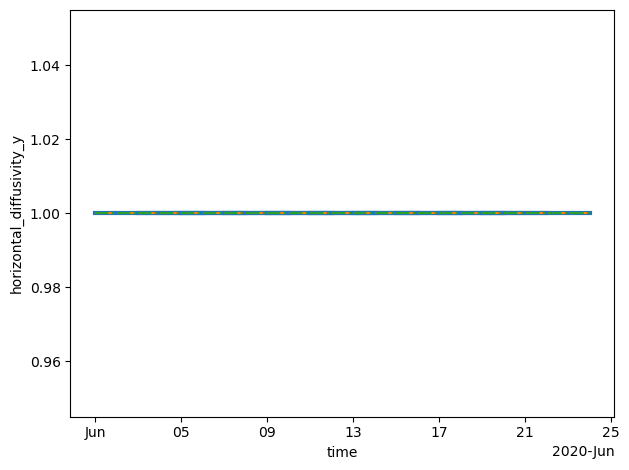

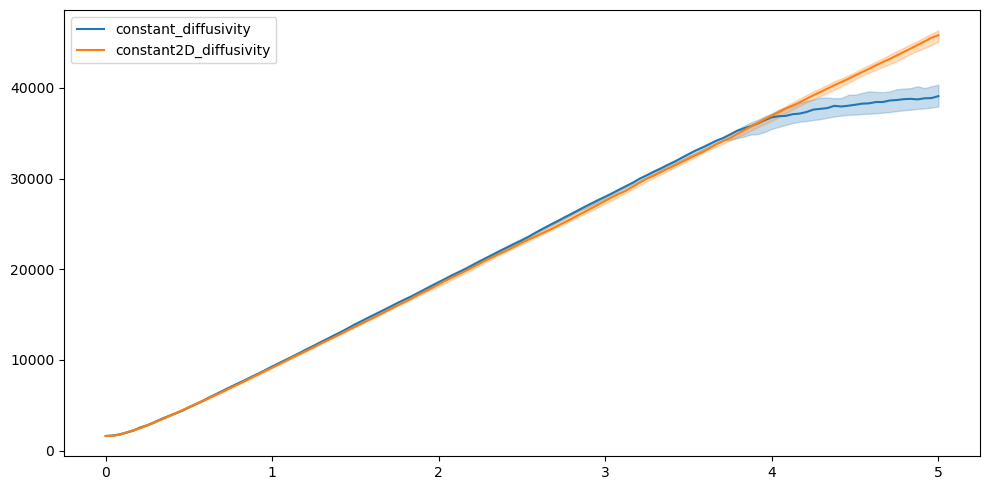

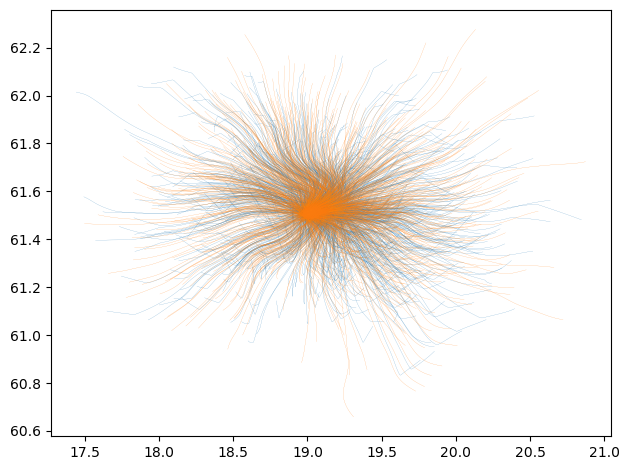

In [41]:
plt.figure()
dt=timedelta(days=5)
for st,startdate in enumerate(startdates[:10]):
    oc1_all  = xr.open_dataset('BS_cmems_'+str(st).zfill(2)+'_constantKh'+str(Kh)+'.nc')
    oc2_all  = xr.open_dataset('BS_cmems_'+str(st).zfill(2)+'_constant2dKh'+str(Kh)+'.nc')
    oc1_all.horizontal_diffusivity.mean('trajectory').plot(ls='-',lw=3,color='C0')
    #oc2_all.horizontal_diffusivity.mean('trajectory').plot(ls='-',color='C1')
    oc2_all.horizontal_diffusivity_x.mean('trajectory').plot(ls='--',color='C1')
    oc2_all.horizontal_diffusivity_y.mean('trajectory').plot(ls='-.',color='C2')

plt.figure(figsize=(10,5))
timeaxis=np.arange(0,(dt.days)*24*3600+1,output_tstep)/(24*3600)
plt.plot(timeaxis,np.nanmedian(np.array(oc1_d),0),color='C0',label='constant_diffusivity')
plt.fill_between(timeaxis,np.percentile(np.array(oc1_d),25,axis=0), np.percentile(np.array(oc1_d),75,axis=0),color='C0',alpha=0.25)
plt.plot(timeaxis,np.nanmedian(np.array(oc2_d),0),color='C1',label='constant2D_diffusivity')
plt.fill_between(timeaxis,np.percentile(np.array(oc2_d),25,axis=0), np.percentile(np.array(oc2_d),75,axis=0),color='C1',alpha=0.25)
plt.legend()

plt.figure()
st=0
Kh1  = xr.open_dataset('BS_cmems_'+str(st).zfill(2)+'_constantKh'+str(Kh)+'.nc')
Kh2  = xr.open_dataset('BS_cmems_'+str(st).zfill(2)+'_constant2dKh'+str(Kh)+'.nc')
plt.plot(Kh1.lon.T,Kh1.lat.T,lw=0.1,color='C0');
plt.plot(Kh2.lon.T,Kh2.lat.T,lw=0.1,color='C1');



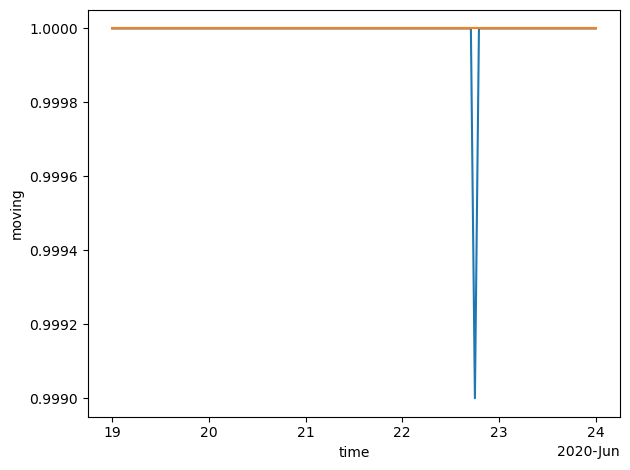

In [26]:
np.mean(oc1_all.moving,0).plot()
np.mean(oc2_all.moving,0).plot()

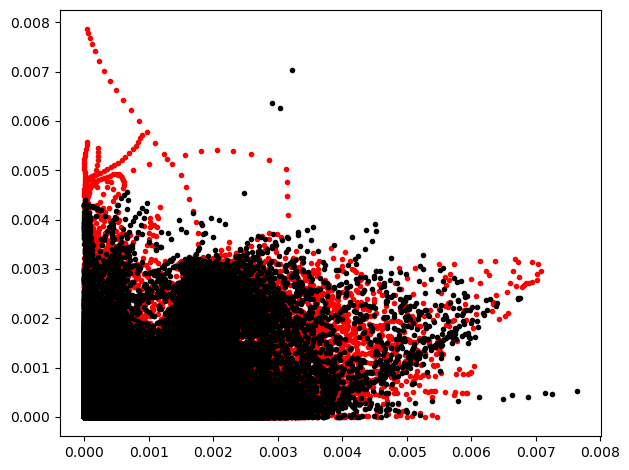

In [32]:
plt.plot(oc2_all.x_sea_water_velocity.T**2,oc2_all.y_sea_water_velocity.T**2,'.r',lw=0.1);
plt.plot(oc1_all.x_sea_water_velocity.T**2,oc1_all.y_sea_water_velocity.T**2,'.k',lw=0.1);
#

## Real 2D diffusivity case

Now that we have established the basics, it's time for a more realistic case. One might have diffusivity estimated from many sources, but here we follow a parameterization by Le Sommer et al (2011). This parameterization estimates subgridscale stirring from the velocity components of the resolved flow.

In [36]:
def subgrid_diffusivity(u,v,longitude,latitude,R=6371E3,C=0.1):
    '''
    Implementation of subgrid scale diffusivity,
    following http://dx.doi.org/10.1016/j.ocemod.2011.03.007 
    '''
    dlat = np.diff(latitude)[0]
    dlon = np.diff(longitude)[0]
    lon2,lat2   = np.meshgrid(longitude.values,latitude.values)
    dlat2 = np.ones(lat2.shape)*dlat
    dlon2 = np.ones(lon2.shape)*dlon
    dy = R*(np.radians(dlat2))
    dx = R*(np.radians(dlon2))*np.cos(np.radians(lat2))
    #
    dudx = u.drop('longitude').drop('latitude').differentiate('longitude')/dx
    dvdx = v.drop('longitude').drop('latitude').differentiate('longitude')/dx
    #
    dudy = u.drop('longitude').drop('latitude').differentiate('latitude')/dy
    dvdy = v.drop('longitude').drop('latitude').differentiate('latitude')/dy
    #
    r=dvdx+dudy
    a=dudx-dvdy
    d=dudx+dvdy
    delta = d/xr.concat([1E-5*xr.ones_like(d),(np.sqrt(r**2+a**2))],dim='dum').max('dum')
    p=np.sqrt(r**2+a**2)+a
    q=np.sqrt(r**2+a**2)-a
    #
    h2=C*dy*dx #slightly tuned
    #
    kx=h2*(1+delta)*p #x-component
    ky=h2*(1+delta)*q #y-component
    kxy=h2*(1+delta)*r #off-diagnogal component
    Kh=h2*(d+np.sqrt(r**2+a**2)) # magnitude
    return Kh.assign_coords({'longitude':longitude,'latitude':latitude}), kx.assign_coords({'longitude':longitude,'latitude':latitude}), ky.assign_coords({'longitude':longitude,'latitude':latitude}), kxy.assign_coords({'longitude':longitude,'latitude':latitude})

Now all we need to do is to add readers for opendrift. Here we add 1) a reader for the magnitude, which will then use a spatially varying, but 1D estimate 2) a reader for the components which will then use a spatially varying 2D tensor representation of diffusivity. Otherwise we are using exactly the same month as for the constant diffusion case.

In [52]:
loglevel=50
#
tstep = 5*60
output_tstep = 3600
# start and end dates
dt=timedelta(days=5)
startdates = np.arange(datetime(2020,6,1),datetime(2020,7,1),timedelta(days=2))
# location, depth, radius and number of particles in seeding
(lon,lat) = (19,61.5)
z = -5.0
radius = 1000
N = 1000
#
for diff2d in [False, True]:
  for st,startdate in enumerate(startdates[:10]):
    print(startdate, diff2d)
    o2 = OceanDrift(loglevel=loglevel)
    o2.set_config('drift:vertical_advection', False)
    o2.set_config('drift:horizontal_mixing_2D', diff2d)
    o2.set_config('general:use_auto_landmask',False)
    o2.set_config('general:coastline_action', 'stranding')
    o2.set_config('seed:ocean_only', True)
    o2.set_config('drift:advection_scheme', 'runge-kutta')
    #
    o2.set_config('drift:stokes_drift', False)
    o2.set_config('drift:wind_drift_depth', 0.0)
    o2.set_config('seed:wind_drift_factor', None)
    # create and add reader for opendrift using cmems reanalysis data
    ds = copernicusmarine.open_dataset(dataset_id='cmems_mod_bal_phy_my_P1D-m',
                                       chunk_size_limit=0)
    reader_cmems = Reader(ds, name='CMEMS Baltic')
    o2.add_reader(reader_cmems,variables=['x_sea_water_velocity','y_sea_water_velocity'])
    
    # open grid file of reanalysis product
    tmp = copernicusmarine.open_dataset(dataset_id='cmems_mod_bal_phy_my_static', chunk_size_limit=0)
    # take bathymetry and change standard name to what opendrift expects
    bathy = tmp.deptho.fillna(0)
    bathy.attrs['standard_name'] = 'sea_floor_depth_below_sea_level'
    # take sea mask and convert to land mask (1: land, 0: sea)
    lmask = 1-tmp.isel(depth=0).mask
    lmask.attrs['standard_name'] = 'land_binary_mask'
    # combine these to xarray dataset
    grid = xr.Dataset(
        data_vars={'sea_floor_depth_below_sea_level': bathy, 'land_binary_mask': lmask.drop_vars('depth')},
        coords=bathy.coords,
    )
    # create reader for opendrift using this dataset
    reader_grid = Reader(grid, name='CMEMS Baltic grid')
    o2.add_reader(reader_grid,variables=['sea_floor_depth_below_sea_level','land_binary_mask'])
    # create reader for horisontal diffusivity
    # set time period and spatial extent (to save memory)
    t1 = startdate
    t2 = startdate+dt
    (lon1,lon2) = (16, 21)
    (lat1,lat2) = (61.0, 62.0)
    # take chosen timespan and spatial extent from current velocity components
    u = ds.uo.sel(time=slice(t1,t2),longitude=slice(lon1,lon2),latitude=slice(lat1,lat2)).fillna(0)
    v = ds.vo.sel(time=slice(t1,t2),longitude=slice(lon1,lon2),latitude=slice(lat1,lat2)).fillna(0)
    # calculate mean over 10 m surface layer
    u2d = u.isel(depth=0) #slice(0,10)).mean(dim='depth')
    v2d = v.isel(depth=0) #slice(0,10)).mean(dim='depth')
    # take these depths to be used later
    #deps = ds.depth.sel(depth=slice(0,10))
    # take chosen spatial extent from grid
    grid_subset = grid.sel(longitude=slice(lon1,lon2),latitude=slice(lat1,lat2))
    # calculate horizontal diffusivity
    kh,kx,ky, kxy = subgrid_diffusivity(u2d,v2d,grid_subset.longitude,grid_subset.latitude)
    # set landpoints to nan
    kh = kh.where(grid_subset.land_binary_mask==0)
    kx = kx.where(grid_subset.land_binary_mask==0)
    ky = kx.where(grid_subset.land_binary_mask==0)
    kxy = kxy.where(grid_subset.land_binary_mask==0)
    kxy = kxy.where(kxy>0, other=0)
    # add standard name (otherwise opendrift does not know what it is)
    kh.attrs['standard_name'] = 'horizontal_diffusivity'
    kh.attrs['units'] = 'm2 s-1'
    kx.attrs['standard_name'] = 'horizontal_diffusivity_x'
    kx.attrs['units'] = 'm2 s-1'
    ky.attrs['standard_name'] = 'horizontal_diffusivity_y'
    ky.attrs['units'] = 'm2 s-1'
    kxy.attrs['standard_name'] = 'horizontal_diffusivity_xy'
    kxy.attrs['units'] = 'm2 s-1'
    # convert to dataset
    ds_kh = kh.to_dataset(name='Kh')
    ds_kx = kx.to_dataset(name='Kx')
    ds_ky = ky.to_dataset(name='Ky')
    ds_kxy = kxy.to_dataset(name='Kxy')
    if not diff2d:
        # save diffusivity to nc file for convenience
        # we do this only for diff2d=False, because the 
        # fields are the same for both cases
        ds_K=xr.merge([ds_kh,ds_kx,ds_ky,ds_kxy]).to_netcdf('K_'+str(st).zfill(2)+'.nc')
    # TODO save to ncfile to check
    # create reader with Kh dataset (name is not relevant)
    reader_kh = Reader(ds_kh, name='Horizontal diffusivity')
    o2.add_reader(reader_kh, variables=['horizontal_diffusivity'])
    if diff2d:
        reader_kx = Reader(ds_kx, name='Horizontal diffusivity x')
        reader_ky = Reader(ds_ky, name='Horizontal diffusivity y')
        reader_kxy = Reader(ds_kxy, name='Horizontal diffusivity xy')
        o2.add_reader(reader_kx, variables=['horizontal_diffusivity_x'])
        o2.add_reader(reader_ky, variables=['horizontal_diffusivity_y'])
        o2.add_reader(reader_kxy, variables=['horizontal_diffusivity_xy'])
    #
    if not diff2d:
        ncfile = 'BS_cmems_'+str(st).zfill(2)+'_variableKh.nc'
    else:
        ncfile = 'BS_cmems_'+str(st).zfill(2)+'_variable2DK.nc'
    #
    o2.seed_elements(lon=lon, lat=lat, z=z, number=N, radius=radius, time=startdate)
    o2.run(end_time=startdate+dt,
            time_step=tstep,
            time_step_output=output_tstep,
            outfile=ncfile)

2020-06-01T00:00:00.000000 False


INFO - 2026-11-23T15:14:03Z - Selected dataset version: "202303"
INFO - 2026-11-23T15:14:03Z - Selected dataset part: "default"
INFO - 2026-11-23T15:14:04Z - Selected dataset version: "202303"
INFO - 2026-11-23T15:14:04Z - Selected dataset part: "bathy"


2020-06-03T00:00:00.000000 False


INFO - 2026-11-23T15:14:31Z - Selected dataset version: "202303"
INFO - 2026-11-23T15:14:31Z - Selected dataset part: "default"
INFO - 2026-11-23T15:14:32Z - Selected dataset version: "202303"
INFO - 2026-11-23T15:14:32Z - Selected dataset part: "bathy"


2020-06-05T00:00:00.000000 False


INFO - 2026-11-23T15:14:58Z - Selected dataset version: "202303"
INFO - 2026-11-23T15:14:58Z - Selected dataset part: "default"
INFO - 2026-11-23T15:15:00Z - Selected dataset version: "202303"
INFO - 2026-11-23T15:15:00Z - Selected dataset part: "bathy"


... (30 outputs left out)

2020-06-17T00:00:00.000000 True


INFO - 2026-11-23T15:36:39Z - Selected dataset version: "202303"
INFO - 2026-11-23T15:36:39Z - Selected dataset part: "default"
INFO - 2026-11-23T15:36:40Z - Selected dataset version: "202303"
INFO - 2026-11-23T15:36:40Z - Selected dataset part: "bathy"


2020-06-19T00:00:00.000000 True


INFO - 2026-11-23T15:38:55Z - Selected dataset version: "202303"
INFO - 2026-11-23T15:38:55Z - Selected dataset part: "default"
INFO - 2026-11-23T15:38:56Z - Selected dataset version: "202303"
INFO - 2026-11-23T15:38:56Z - Selected dataset part: "bathy"


In [53]:
oc_d=[]
o_d=[]
o2_d=[]
for st,startdate in enumerate(startdates[:10]):
    oc_all = xr.open_dataset('BS_cmems_'+str(st).zfill(2)+'_constantKh1.nc')
    o_all  = xr.open_dataset('BS_cmems_'+str(st).zfill(2)+'_variableKh.nc')
    o2_all  = xr.open_dataset('BS_cmems_'+str(st).zfill(2)+'_variable2DK.nc')
    oc_distance  = np.ones(oc_all.time.size)*np.nan
    o_distance = np.ones(o_all.time.size)*np.nan
    o2_distance = np.ones(o2_all.time.size)*np.nan
    for t,time in enumerate(oc_all.time):
        oc_distance[t]=np.nanmedian(gsw.distance(oc_all.lon[:,t],oc_all.lat[:,t],axis=0))
    for t,time in enumerate(o_all.time):
        o_distance[t]=np.nanmedian(gsw.distance(o_all.lon[:,t],o_all.lat[:,t],axis=0))
    for t,time in enumerate(o2_all.time):
        o2_distance[t]=np.nanmedian(gsw.distance(o2_all.lon[:,t],o2_all.lat[:,t],axis=0))
    #
    oc_d.append(oc_distance)
    o_d.append(o_distance)
    o2_d.append(o2_distance)

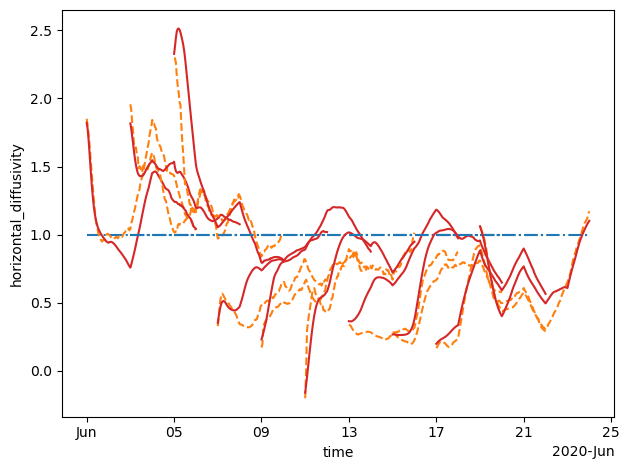

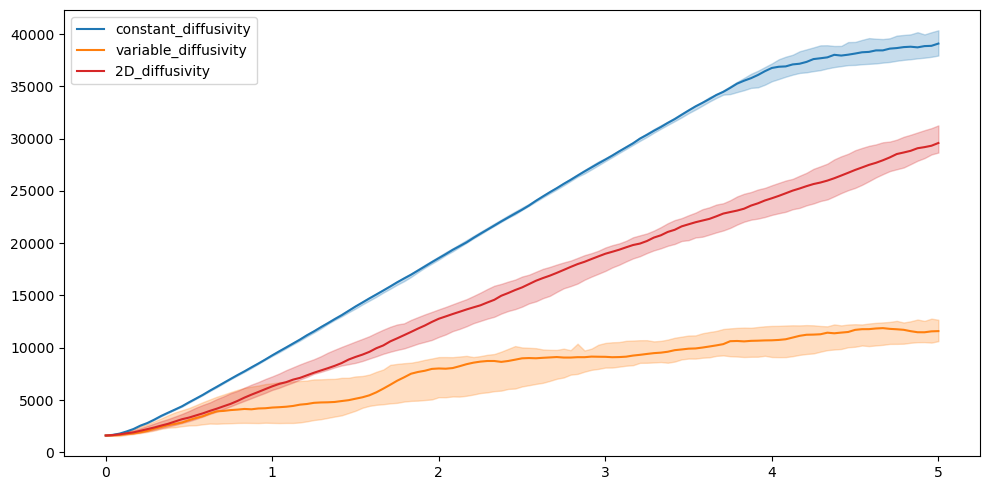

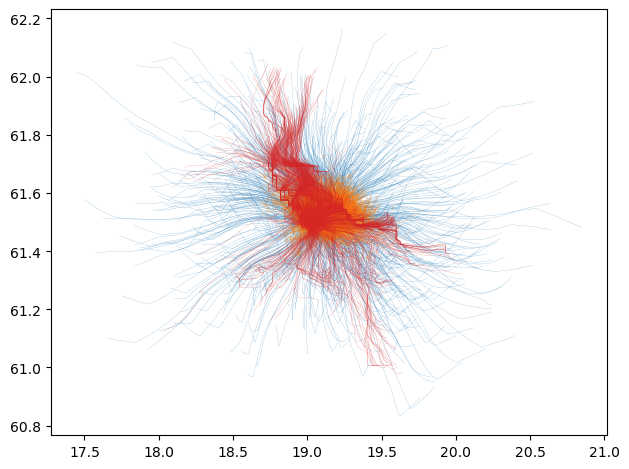

In [56]:
plt.figure()
for st,startdate in enumerate(startdates[:10]):
    oc_all = xr.open_dataset('BS_cmems_'+str(st).zfill(2)+'_constantKh1.nc')
    o_all  = xr.open_dataset('BS_cmems_'+str(st).zfill(2)+'_variableKh.nc')
    o2_all = xr.open_dataset('BS_cmems_'+str(st).zfill(2)+'_variable2DK.nc')
    oc_all.horizontal_diffusivity.mean('trajectory').plot(ls='-.',color='C0')
    o_all.horizontal_diffusivity.median('trajectory').plot(ls='--',color='C1')
    o2_all.horizontal_diffusivity.mean('trajectory').plot(ls='-',color='C3')

plt.figure(figsize=(10,5))
timeaxis=np.arange(0,(dt.days)*24*3600+1,output_tstep)/(24*3600)
plt.plot(timeaxis,np.median(np.array(oc_d),0),color='C0',label='constant_diffusivity')
plt.fill_between(timeaxis,np.percentile(np.array(oc_d),25,axis=0), np.percentile(np.array(oc_d),75,axis=0),color='C0',alpha=0.25)
plt.plot(timeaxis,np.median(np.array(o_d),0),color='C1',label='variable_diffusivity')
plt.fill_between(timeaxis,np.percentile(np.array(o_d),25,axis=0), np.percentile(np.array(o_d),75,axis=0),color='C1',alpha=0.25)
plt.plot(timeaxis,np.median(np.array(o2_d),0),color='C3',label='2D_diffusivity')
plt.fill_between(timeaxis,np.percentile(np.array(o2_d),25,axis=0), np.percentile(np.array(o2_d),75,axis=0),color='C3',alpha=0.25)
plt.legend()

plt.figure()
st=0
Kh1  = xr.open_dataset('BS_cmems_'+str(st).zfill(2)+'_constantKh1.nc')
Kh   = xr.open_dataset('BS_cmems_'+str(st).zfill(2)+'_variableKh.nc')
K2D  = xr.open_dataset('BS_cmems_'+str(st).zfill(2)+'_variable2DK.nc')
plt.plot(Kh1.lon.T,Kh1.lat.T,lw=0.1,color='C0');
plt.plot(Kh.lon.T,Kh.lat.T,lw=0.1,color='C1');
plt.plot(K2D.lon.T,K2D.lat.T,lw=0.1,color='C3');